In [10]:
from pathlib import Path

import pandas as pd

ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / 'pnas_report/data/dataset_graph/outsideprem_toprem_eligible_transfers.csv.gz').is_file()
)
DATA_PATH = ROOT / 'pnas_report/data/dataset_graph/outsideprem_toprem_eligible_transfers.csv.gz'

data_full = pd.read_csv(DATA_PATH, low_memory=False)
data_full.head()

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,from_club_name,to_club_name,transfer_fee,market_value_in_eur_transfer,player_name,...,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur_player,highest_market_value_in_eur,age_when_transferred
0,1045344,2027-06-30,26/27,200,15,Utrecht,Leverkusen,0.0,5000000.0,Artem Stepanov,...,https://img.a.transfermarkt.technology/portrai...,7.0,1.0,NaN,https://www.transfermarkt.co.uk/artem-stepanov...,NL1,FC Utrecht,5000000.0,5000000.0,19
1,1052439,2027-06-30,26/27,209,631,River Plate,Chelsea,0.0,8000000.0,Kendry Páez,...,https://img.a.transfermarkt.technology/portrai...,27.0,2.0,NaN,https://www.transfermarkt.co.uk/kendry-paez/pr...,FR1,RC Strasbourg Alsace,8000000.0,12000000.0,20
2,1154876,2027-06-30,26/27,798,39,Excelsior,Mainz,0.0,450000.0,Kasey Bos,...,https://img.a.transfermarkt.technology/portrai...,0.0,0.0,3433.0,https://www.transfermarkt.co.uk/kasey-bos/prof...,L1,1.FSV Mainz 05,450000.0,450000.0,23
3,1043003,2027-01-27,26/27,114,405,Besiktas,Aston Villa,0.0,5000000.0,Yasin Özcan,...,https://img.a.transfermarkt.technology/portrai...,20.0,0.0,NaN,https://www.transfermarkt.co.uk/yasin-ozcan/pr...,BE1,RSC Anderlecht,5000000.0,7500000.0,20
4,787618,2026-12-31,26/27,1444,46,Racing Club,Inter,0.0,7500000.0,Valentín Carboni,...,https://img.a.transfermarkt.technology/portrai...,3.0,0.0,NaN,https://www.transfermarkt.co.uk/valentin-carbo...,ARG1,Racing Club Asociación Civil de Avellaneda,7500000.0,15000000.0,21


In [11]:
import networkx as nx

transfer_counts = (
    data_full.groupby(['from_club_id', 'to_club_id'])
    .size().reset_index(name='weight')
)
graph = nx.from_pandas_edgelist(
    transfer_counts, source='from_club_id', target='to_club_id',
    edge_attr='weight', create_using=nx.DiGraph,
)

club_labels = dict(zip(data_full['from_club_id'], data_full['from_club_name']))
club_labels.update(zip(data_full['to_club_id'], data_full['to_club_name']))
nx.set_node_attributes(graph, club_labels, 'label')

graph

In [3]:
degree_df = pd.DataFrame({
    'in_degree': dict(graph.in_degree()),
    'out_degree': dict(graph.out_degree()),
    # Reciprocal degree counts neighbors connected in both directions.
    'reciprocal_degree': {
        node: len(set(graph.predecessors(node)) & set(graph.successors(node)))
        for node in graph
    },
}).rename_axis('node').reset_index()
degree_df.insert(1, 'club_name', degree_df['node'].map(club_labels))

degree_df.sort_values('in_degree', ascending=False).head(10)

,node,club_name,in_degree,out_degree,reciprocal_degree
42,410,Udinese,152,134,102
91,252,Genoa,145,135,109
84,46,Inter,138,150,116
39,276,Hellas Verona,138,118,98
109,430,Fiorentina,129,130,97
92,281,Man City,127,0,0
78,12,Roma,123,127,98
117,631,Chelsea,115,0,0
121,800,Atalanta BC,112,104,84
106,416,Torino,110,109,91


In [4]:
network_summary = pd.Series({
    'Number of nodes': graph.number_of_nodes(),
    'Number of directed edges': graph.number_of_edges(),
    'Maximum in-degree': degree_df['in_degree'].max(),
    'Maximum out-degree': degree_df['out_degree'].max(),
    'Maximum reciprocal degree': degree_df['reciprocal_degree'].max(),
    'Mean in-degree': degree_df['in_degree'].mean().round(2),
    'Mean out-degree': degree_df['out_degree'].mean().round(2),
    'Mean reciprocal degree': degree_df['reciprocal_degree'].mean().round(2),
    'Median in-degree': degree_df['in_degree'].median(),
    'Median out-degree': degree_df['out_degree'].median(),
    'Median reciprocal degree': degree_df['reciprocal_degree'].median(),
}, name='Value', dtype=object).rename_axis('Statistic').to_frame()

network_summary

,Value
Statistic,
Number of nodes,1254
Number of directed edges,12794
Maximum in-degree,152
Maximum out-degree,150
Maximum reciprocal degree,116
Mean in-degree,10.2
Mean out-degree,10.2
Mean reciprocal degree,6.12
Median in-degree,2.0


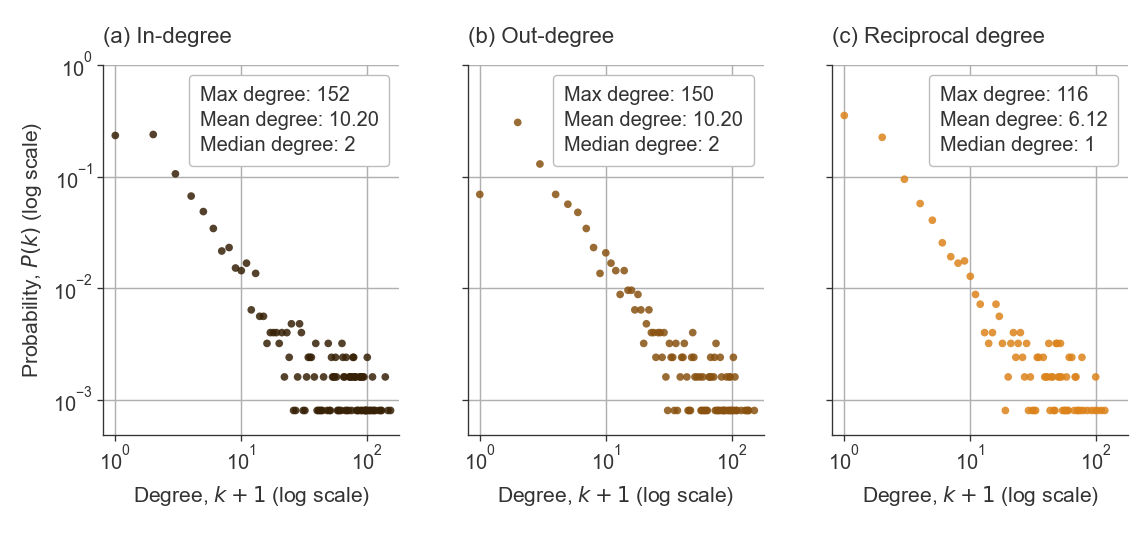

In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

OUTPUT_DIR = ROOT / 'pnas_report/output/club_transfer_network_findings'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plot_colors = ['#372107', '#895211', '#DC831B', '#F9AB50', '#FBC382']
plot_style = {
    'font.family': 'Arial',
    'font.size': 9.5,
    'mathtext.fontset': 'custom',
    'mathtext.rm': 'Arial',
    'mathtext.it': 'Arial:italic',
    'mathtext.bf': 'Arial:bold',
    'text.color': '#333333',
    'axes.titlesize': 10,
    'axes.titlecolor': '#333333',
    'axes.labelsize': 9.5,
    'axes.labelcolor': '#333333',
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.6,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'legend.fontsize': 9,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'figure.dpi': 160,
    'savefig.dpi': 600,
    'savefig.bbox': None,
    'pdf.fonttype': 42,
    'svg.fonttype': 'none',
}
degree_columns = [
    ('in_degree', 'In-degree', plot_colors[0]),
    ('out_degree', 'Out-degree', plot_colors[1]),
    ('reciprocal_degree', 'Reciprocal degree', plot_colors[2]),
]


def export_figure(figure, stem):
    for extension in ('pdf', 'png', 'svg'):
        figure.savefig(OUTPUT_DIR / f'{stem}.{extension}')


def draw_degree(ax, degree_column, color):
    probability = degree_df[degree_column].value_counts(normalize=True).sort_index()
    k_plus_one = probability.index.to_numpy() + 1
    ax.scatter(
        k_plus_one, probability.to_numpy(), s=12, color=color,
        alpha=0.85, edgecolors='none',
    )
    # Preserve the log-log encoding and k + 1 shift, including degree-zero clubs.
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(0.8, 180)
    ax.set_ylim(0.6 / len(degree_df), 1)
    ax.set_xlabel(r'Degree, $k + 1$ (log scale)')
    ax.grid(which='major', color='#B0B0B0', linewidth=0.65)
    ax.set_axisbelow(True)
    ax.tick_params(which='both', direction='out', length=2.5, width=0.6, pad=2)
    ax.tick_params(which='minor', bottom=False, left=False)

    summary = network_summary['Value']
    degree_name = degree_column.replace('_', '-').replace('reciprocal-degree', 'reciprocal degree')
    labels = [
        f"Max degree: {summary[f'Maximum {degree_name}']:g}",
        f"Mean degree: {summary[f'Mean {degree_name}']:.2f}",
        f"Median degree: {summary[f'Median {degree_name}']:g}",
    ]
    legend = ax.legend(
        handles=[Line2D([], [], linestyle='none') for _ in labels],
        labels=labels, loc='upper right', ncol=1, frameon=True, fancybox=True,
        facecolor='white', edgecolor='#BBBBBB', framealpha=1,
        handlelength=0, handletextpad=0, borderpad=0.55, labelspacing=0.3,
    )
    legend.get_frame().set_linewidth(0.6)


with plt.rc_context(plot_style):
    fig, axes = plt.subplots(1, 3, figsize=(7.16, 3.4), sharey=True)
    fig.subplots_adjust(left=0.09, right=0.985, bottom=0.20, top=0.88, wspace=0.23)
    for col, (degree_column, title, color) in enumerate(degree_columns):
        draw_degree(axes[col], degree_column, color)
        axes[col].set_title(f'({chr(ord("a") + col)}) {title}', loc='left', pad=10)
    axes[0].set_ylabel(r'Probability, $P(k)$ (log scale)')
    export_figure(fig, 'club_transfer_degree_distributions')
    # Retain the existing report image path.
    fig.savefig(ROOT / 'pnas_report/figures/degree_distributions.png')
    plt.show()

    for degree_column, title, color in degree_columns:
        standalone, ax = plt.subplots(figsize=(3.58, 3.2))
        standalone.subplots_adjust(left=0.19, right=0.97, bottom=0.17, top=0.96)
        draw_degree(ax, degree_column, color)
        ax.set_ylabel(r'Probability, $P(k)$ (log scale)')
        export_figure(standalone, f'{degree_column}_distribution')
        plt.close(standalone)


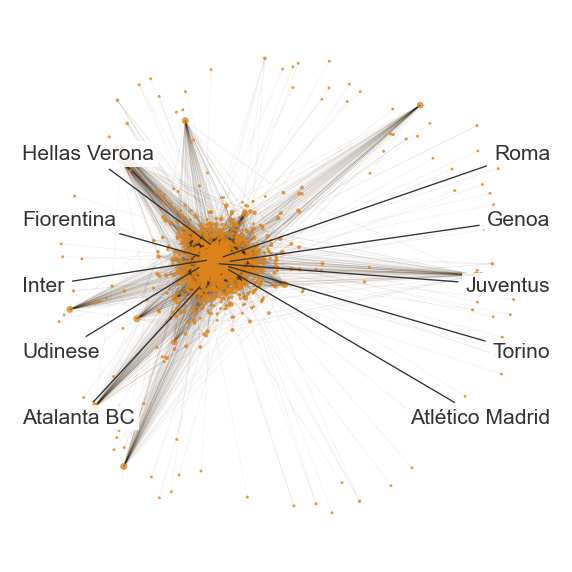

In [15]:
import matplotlib.pyplot as plt
import numpy as np

strength = dict(graph.degree(weight='weight'))
pos = nx.spring_layout(graph, seed=42, weight='weight', iterations=30)

with plt.rc_context(plot_style):
    fig, ax = plt.subplots(figsize=(3.58, 3.58))
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=0.98)
    nx.draw_networkx_edges(
        graph, pos, ax=ax, arrows=False, edge_color=plot_colors[0], alpha=0.08,
        width=[0.15 + 0.15 * np.log1p(edge['weight']) for _, _, edge in graph.edges(data=True)],
    )
    nx.draw_networkx_nodes(
        graph, pos, ax=ax,
        node_size=[0.25 * (4 + 3 * np.sqrt(strength[node])) for node in graph],
        node_color=plot_colors[2], alpha=0.8, linewidths=0,
    )

    top_clubs = sorted(strength, key=strength.get, reverse=True)[:10]
    # Keep the same ten clubs and node positions; separate their labels for print.
    left_to_right = sorted(top_clubs, key=lambda node: pos[node][0])
    for side, nodes in enumerate((left_to_right[:5], left_to_right[5:])):
        nodes = sorted(nodes, key=lambda node: pos[node][1])
        for node, label_y in zip(nodes, np.linspace(0.26, 0.74, len(nodes))):
            ax.annotate(
                graph.nodes[node]['label'], xy=pos[node], xycoords='data',
                xytext=(0.02 if side == 0 else 0.98, label_y),
                textcoords='axes fraction', ha='left' if side == 0 else 'right',
                va='center', fontsize=9.5, color='#333333',
                bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9, 'pad': 1.5},
                arrowprops={'arrowstyle': '-', 'color': '#333333', 'linewidth': 0.6},
            )
    ax.set_axis_off()
    export_figure(fig, 'club_transfer_network')
    fig.savefig(ROOT / 'pnas_report/figures/transfer_graphs.png')
    plt.show()
